In [0]:
%pip install spacy nltk
import pandas as pd
import numpy as np
import spacy
import nltk
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns


Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:

# Download required NLTK data
nltk.download(['punkt', 'stopwords', 'wordnet'])

# Load SpaCy model
spacy.cli.download("en_core_web_sm")
nlp = spacy.load('en_core_web_sm')


[nltk_data] Downloading package punkt to
[nltk_data]     /home/spark-9e29e688-5ead-4093-b5ef-79/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/spark-9e29e688-5ead-4093-b5ef-79/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/spark-9e29e688-5ead-4093-b5ef-79/nltk_data...


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 123.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in an interactive Python session, you may need to exit and restart
Python to load all the package's dependencies. You can exit with Ctrl-D (or
Ctrl-Z and Enter on Windows).


In [0]:
# Load dataset (using 20 newsgroups dataset)
def prepare_dataset():
    # Get specific categories for binary classification
    categories = ['rec.sport.baseball', 'sci.space']
    newsgroups = fetch_20newsgroups(subset='all', categories=categories,
                                  remove=('headers', 'footers', 'quotes'))
    
    # Create DataFrame
    df = pd.DataFrame({
        'text': newsgroups.data,
        'label': newsgroups.target
    })
    
    # Clean the dataset
    df = df.dropna()
    return df


In [0]:
# Modern text preprocessing function
def preprocess_text(text, remove_stopwords=True):
    # Process with SpaCy
    doc = nlp(text)
    
    # Basic cleaning
    tokens = [token.lemma_.lower() for token in doc
             if token.is_alpha and not token.is_space]
    
    # Optional stopword removal
    if remove_stopwords:
        tokens = [token for token in tokens 
                 if not token in nlp.Defaults.stop_words]
    
    return " ".join(tokens)


In [0]:
# Data preparation and model training
def train_models(df):
    # Preprocess texts
    print("Preprocessing texts...")
    df['processed_text'] = df['text'].apply(preprocess_text)
    
    # Vectorize
    print("Vectorizing texts...")
    vectorizer = TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2
    )
    
    X = vectorizer.fit_transform(df['processed_text'])
    y = df['label']

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # Train models
    models = {
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
        'Gradient Boosting': GradientBoostingClassifier(random_state=42)
    }
    
    results = {}
    for name, model in models.items():
        print(f"\nTraining {name}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        results[name] = classification_report(y_test, y_pred, output_dict=True)
    
    return results, vectorizer, models


In [0]:
# Visualization functions
def plot_results(results):
    metrics = ['precision', 'recall', 'f1-score']
    
    plt.figure(figsize=(15, 5))
    for i, metric in enumerate(metrics, 1):
        plt.subplot(1, 3, i)
        scores = [res['weighted avg'][metric] for res in results.values()]
        plt.bar(results.keys(), scores)
        plt.title(f'Weighted Average {metric.title()}')
        plt.xticks(rotation=45)
    
    plt.tight_layout()
    plt.show()


In [0]:
# Feature importance analysis
def analyze_features(vectorizer, model, n_top=20):
    if hasattr(model, 'feature_importances_'):
        feature_importance = pd.DataFrame({
            'feature': vectorizer.get_feature_names_out(),
            'importance': model.feature_importances_
        })
        
        top_features = feature_importance.nlargest(n_top, 'importance')
        
        plt.figure(figsize=(12, 6))
        sns.barplot(data=top_features, x='importance', y='feature')
        plt.title(f'Top {n_top} Most Important Features')
        plt.tight_layout()
        plt.show()
        
        return top_features
    else:
        print("Model doesn't support feature importance analysis")
        return None


Loading dataset...

Dataset overview:
Total samples: 1981
Label distribution:
label
0    994
1    987
Name: count, dtype: int64
Preprocessing texts...
Vectorizing texts...

Training Random Forest...

Training Gradient Boosting...

Model Performance Comparison:

Random Forest:
              precision    recall  f1-score    support
0              0.850467  0.978495  0.910000  186.00000
1              0.978142  0.848341  0.908629  211.00000
accuracy       0.909320  0.909320  0.909320    0.90932
macro avg      0.914305  0.913418  0.909315  397.00000
weighted avg   0.918325  0.909320  0.909272  397.00000

Gradient Boosting:
              precision    recall  f1-score     support
0              0.829493  0.967742  0.893300  186.000000
1              0.966667  0.824645  0.890026  211.000000
accuracy       0.891688  0.891688  0.891688    0.891688
macro avg      0.898080  0.896193  0.891663  397.000000
weighted avg   0.902399  0.891688  0.891560  397.000000


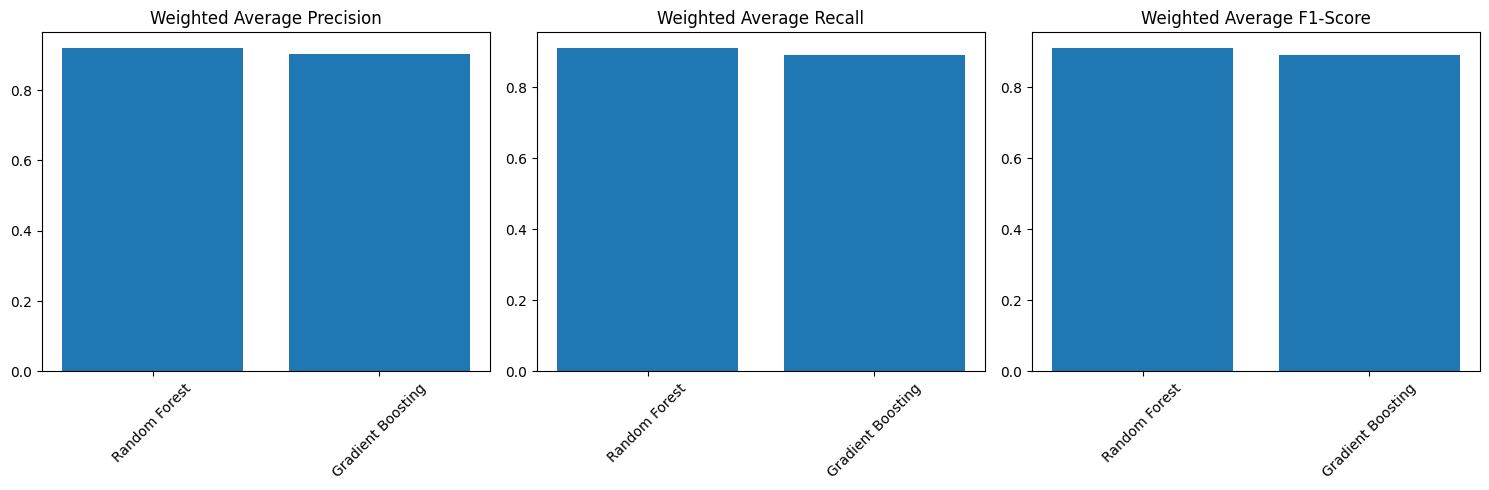

In [0]:
# Main execution
if __name__ == "__main__":
    print("Loading dataset...")
    df = prepare_dataset()
    
    print("\nDataset overview:")
    print(f"Total samples: {len(df)}")
    print(f"Label distribution:\n{df['label'].value_counts()}")
    
    # Train models and get results
    results, vectorizer, models = train_models(df)
    
    # Display results
    print("\nModel Performance Comparison:")
    for name, result in results.items():
        print(f"\n{name}:")
        print(pd.DataFrame(result).T)
    
    # Create visualizations
    plot_results(results)



Analyzing feature importance...


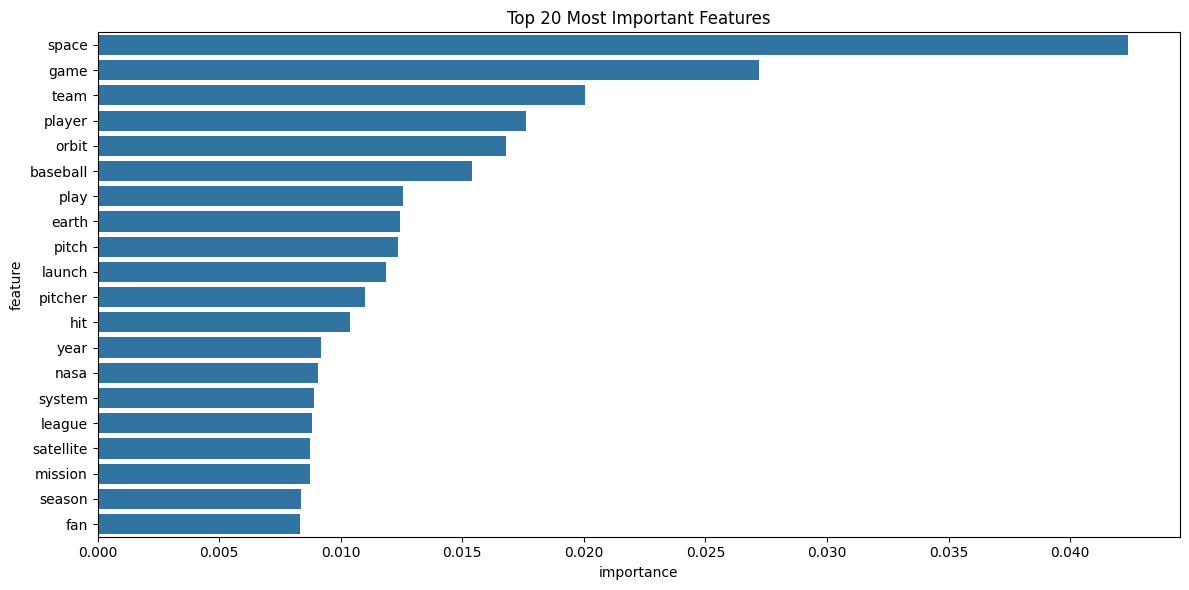


Top 20 most important features:
        feature  importance
4110      space    0.042402
1715       game    0.027202
4404       team    0.020051
3333     player    0.017599
3086      orbit    0.016779
403    baseball    0.015406
3328       play    0.012557
1261      earth    0.012434
3291      pitch    0.012367
2381     launch    0.011876
3295    pitcher    0.011011
1941        hit    0.010397
4966       year    0.009182
2895       nasa    0.009082
4382     system    0.008907
2414     league    0.008800
3853  satellite    0.008729
2810    mission    0.008719
3907     season    0.008355
1515        fan    0.008312


In [0]:
    # Analyze feature importance for Random Forest
    print("\nAnalyzing feature importance...")
    rf_model = models['Random Forest']
    important_features = analyze_features(vectorizer, rf_model)
    if important_features is not None:
        print("\nTop 20 most important features:")
        print(important_features)
